In [396]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob
import subprocess
import tempfile
from os.path import dirname

In [397]:
!ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/*/vamb_multi/umap_vamb.tsv

/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E01_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E01_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E02_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E02_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E03_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_3/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E07_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E07_2/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E09_1/vamb_multi/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E11_

In [398]:
sample = "E06_1"

binning_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir"
taxo_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir"

In [399]:
df_umap_coords = pd.read_csv(f"{binning_dir}/{sample}/vamb_multi/umap_vamb.tsv", sep = '\t')
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,3300061567_Ga0589710_0000001,-3.926890,10.942149,3300061567
1,3300061567_Ga0589710_0000002,-3.814041,11.174147,3300061567
2,3300061567_Ga0589710_0000003,-4.090533,10.532524,3300061567
3,3300061567_Ga0589710_0000004,-3.892994,10.792562,3300061567
4,3300061567_Ga0589710_0000005,-4.522960,10.661549,3300061567


/gpfs/home/qcf21tku/.conda/envs/bio/lib/python3.9/site-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/gpfs/home/qcf21tku/.conda/envs/bio/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


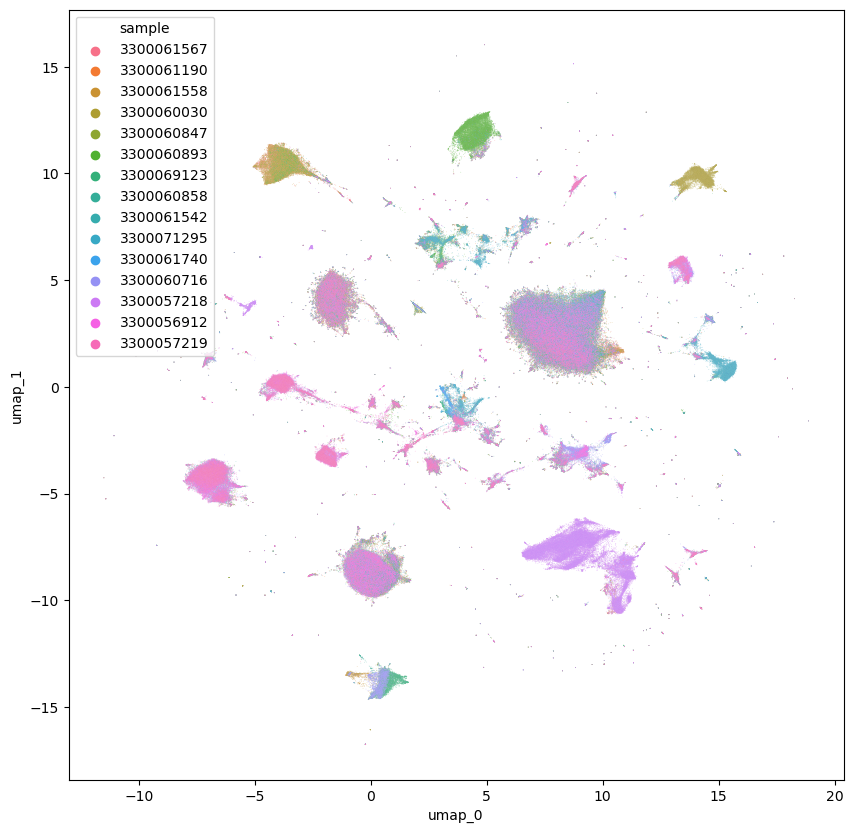

In [400]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df_umap_coords, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'sample',
    alpha = 0.5
)

In [401]:
single_samples = list(set(df_umap_coords['sample']))

def make_taxo_df(sample_id):
    df = pd.read_csv(f"{taxo_dir}/{sample_id}/{sample_id}.faa.mms2lca", sep = '\t')
    df['sample'] = sample_id
    df['contig_id'] = df['sample'] + '_' + df['contig_id']
    return df

df_taxo = pd.concat(
    make_taxo_df(s) for s in single_samples
)

df = pd.merge(
    df_umap_coords, 
    df_taxo, 
    on = ['contig_id', 'sample'],
    how = 'left'
).fillna("Unknown")

In [402]:
#top_10 = list(df.groupby('name').count().sort_values('contig_id', ascending = False).head(10).index)

favourite_groups = [
    "Bacillariophyta", 
    "Nucleocytoviricota", 
    "Mamiellophyceae",
    "Dinophyceae",
    "Metazoa",
    "Cryptophyceae",
    "Haptophyta", 
    "Chlorophyta", 
    "Euglenozoa",
    "Ciliophora",
    "Labyrinthulomycetes", 
    "Chrysophyceae", 
    "Choanoflagellata", 
    "Microbotryomycetes", 
    "Amoebozoa", 
    "Ochrophyta", 
    "Chytridiomycota"
]


def simplify_name(row):
    if row.superkingdom in ["Bacteria", "Archaea"]:
        return "Prokaryota"
    
    if row.superkingdom == "Unknown":
        if row['name'] == "Viruses":
            return "Viruses"
        return "Unknown"
    
    for x in favourite_groups:
        if x in row.lineage:
            return x

    if row.superkingdom == "Virus":
        return "Viruses"
    
    return row.superkingdom
    
    
df['name_simple'] = df.apply(simplify_name, axis = 1)

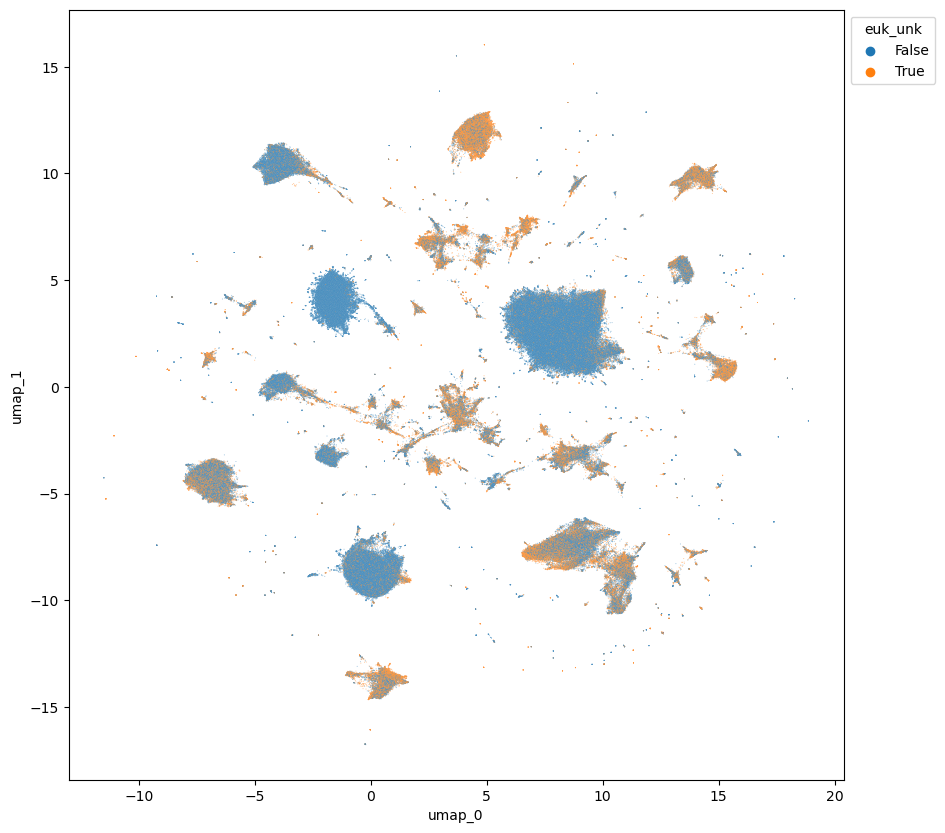

In [403]:
df['euk_unk'] = df.name_simple.isin(["Unknown", "Eukaryota"])

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df,
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'euk_unk',
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

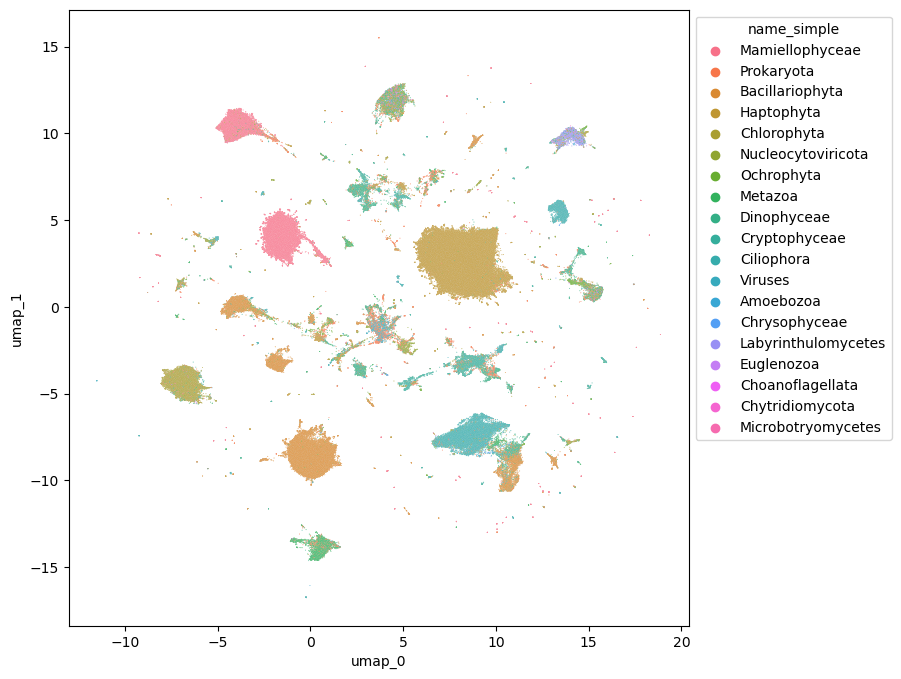

In [404]:
plt.figure(figsize = (8, 8))
ax = sns.scatterplot(
    data = df[~df.name_simple.isin(["Unknown", "Eukaryota"])],
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'name_simple',
    alpha = 0.85
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [405]:
# Below here is done on a per-sample basis... Don't rerun!


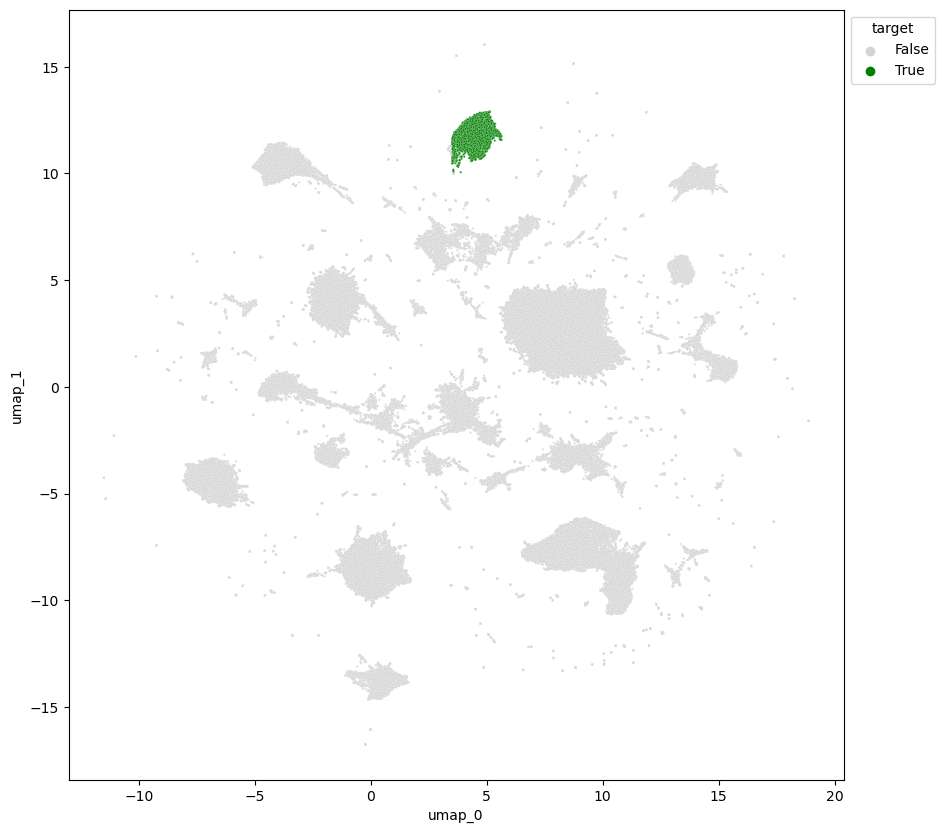

In [451]:
df['target'] = ((df.umap_1 > 10) & (df.umap_1 < 15) & (df.umap_0 > 3.5) & (df.umap_0 < 6.5))

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df,
    x = 'umap_0', 
    y = 'umap_1', 
    s = 2.5, 
    hue = 'target', palette = ['lightgrey', 'green'],
    alpha = 0.85
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [408]:
! cat {binning_dir}/{sample}/all_bins_multi_auto_eukcc/eukcc.csv

! wc -m {binning_dir}/{sample}/all_bins_multi_auto/*.fna | sort -nr -k 1

cat: /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto_eukcc/eukcc.csv: No such file or directory
2085685123 total
  61389211 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto/mbat_multi.92_3300057218.fna
  56603683 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto/mbat_multi.37_3300061567.fna
  55785416 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto/mbat_multi.37_3300061558.fna
  46907586 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto/mbat_multi.66_3300071295.fna
  46117113 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto/mbat_multi.48_3300060716.fna
  42054170 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto/mbat_multi.66_3300060716.fna
  41243204 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_auto/mbat_multi.48_3300056912.fna
  40992860 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_

In [450]:
! wc -m {binning_dir}/{sample}/all_bins_multi_manual/*.fna

 263647113 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/bacillariophyta.1.split_1_v1.fna
  48563271 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/bacillariophyta.2.split_1_v1.fna
 141160920 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/chlorophyta.1.split_1_v1.fna
  23899806 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/ciliophora.1.split_1_v1.fna
 427679915 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/haptophyta.1.split_1_v1.fna
  40518815 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/labyrinthulomycetes.1.split_1_v1.fna
 191561521 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/mameillophyceae.1.split_1_v1.fna
 256393355 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/mameillophyceae.2.split_1_v1.fna
  39896350 /gpfs/data/mock_lab/will/mosaic_tmp/bin

In [452]:
df[df.target].groupby(
    'name_simple'
)[['contig_id']].count().sort_values('contig_id', ascending = False).head(10)

,contig_id
name_simple,
Eukaryota,7410
Unknown,7264
Ochrophyta,1451
Dinophyceae,1031
Haptophyta,851
Metazoa,395
Prokaryota,384
Choanoflagellata,356
Bacillariophyta,341


In [411]:
df[df.target].lineage.value_counts()

Unknown                                                                                                                                                                                                                                                                                                                                                   53247
Eukaryota;Haptista;Haptophyta;Prymnesiophyceae;Phaeocystales;Phaeocystaceae;Phaeocystis;Phaeocystis antarctica                                                                                                                                                                                                                                            53105
Eukaryota;Haptista;Haptophyta;Prymnesiophyceae;Phaeocystales;Phaeocystaceae;Phaeocystis                                                                                                                                                                                                                 

In [412]:
def extract_contigs(df, path_to_contigs, output_path, contig_column = 'contig_id'):
    """
    Extract contigs based on a 'contig_id' column in a DataFrame.

    Args:
        df (pd.DataFrame): The DataFrame containing contig IDs.
        contig_column (str): The name of the column with contig IDs.
        path_to_contigs (str): Path to the file containing all contigs (FASTA).
        output_path (str): Path to save the extracted contigs (FASTA).
    """
    # Ensure the contig_column exists
    if contig_column not in df.columns:
        raise ValueError(f"Column '{contig_column}' not found in DataFrame.")

    # Extract unique contig IDs
    contig_ids = df[contig_column].drop_duplicates().tolist()

    # Use a temporary file to hold contig IDs
    with tempfile.NamedTemporaryFile(mode="w", delete=True) as tmpfile:
        for contig_id in contig_ids:
            tmpfile.write(f"{contig_id}\n")
        tmpfile.flush()  # Ensure all data is written to the file before reading

        # Run seqkit grep to extract matching contigs
        try:
            subprocess.run(["mkdir", "-p", dirname(output_path)])
            subprocess.run(
                [
                    "seqkit", "grep",
                    "-f", tmpfile.name,
                    "-o", output_path,
                    path_to_contigs
                ],
                check=True
            )
            print(f"Contigs extracted successfully to {output_path}")
        except subprocess.CalledProcessError as e:
            print(f"Error running seqkit grep: {e}")



In [453]:
#extract_contigs(
#    df[df.target], 
#    f"{binning_dir}/{sample}/{sample}.euks.fna", 
#    f"{binning_dir}/{sample}/all_bins_multi_manual/ochrophyta.1.split_1_v1.fna"
#)

[INFO] 20418 patterns loaded from file


Contigs extracted successfully to /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_multi_manual/ochrophyta.1.split_1_v1.fna
